In [6]:
!pip install pandas
!pip install matplotlib
!pip install seaborn


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
  Using cached matplotlib-3.10.8-cp311-cp311-macosx_11_0_arm64.whl.metadata (52 kB)
  Using cached contourpy-1.3.3-cp311-cp311-macosx_11_0_arm64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.61.1-cp311-cp311-macosx_10_9_universal2.whl.metadata (114 kB)
  Using cached kiwisolver-1.4.9-cp311-cp311-macosx_11_0_arm64.whl.metadata (6.3 kB)
  Using cached pillow-12.1.1-cp311-cp311-macosx_11_0_arm64.whl.metadata (8.8 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
Using cached matplotlib-3.10.8-cp311-cp311-macosx_11_0_arm64.whl (8.1 MB)
Using cached contourpy-1.3.3-cp311-cp311-macosx_11_0_arm64.whl (270 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.61.1-cp311-cp311-macosx_10_9_universal2.whl (2.9 MB)
Using cached kiwisolver-1.4.9-cp311-cp311-macosx_11_0_arm64.w

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

athletes = pd.read_csv("../data/athlete_events.csv")
regions = pd.read_csv("../data/noc_regions.csv")

athletes.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [15]:
code_map = {
    "USA": "USA",
    "URS": "Soviet/Russia",
    "RUS": "Soviet/Russia",
    "CHN": "China",
}

ath = athletes[athletes['NOC'].isin(code_map.keys())].copy()
ath['country_group'] = ath['NOC'].map(code_map)

medals = ath[ath['Medal'].notna()].copy()
medals.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,country_group
163,67,Mariya Vasilyevna Abakumova (-Tarabina),F,22.0,179.0,80.0,Russia,RUS,2008 Summer,2008,Summer,Beijing,Athletics,Athletics Women's Javelin Throw,Silver,Soviet/Russia
186,84,Stephen Anthony Abas,M,26.0,165.0,55.0,United States,USA,2004 Summer,2004,Summer,Athina,Wrestling,"Wrestling Men's Featherweight, Freestyle",Silver,USA
195,90,Tamila Rashidovna Abasova,F,21.0,163.0,60.0,Russia,RUS,2004 Summer,2004,Summer,Athina,Cycling,Cycling Women's Sprint,Silver,Soviet/Russia
278,145,Jeremy Abbott,M,28.0,175.0,70.0,United States,USA,2014 Winter,2014,Winter,Sochi,Figure Skating,Figure Skating Mixed Team,Bronze,USA
283,150,Margaret Ives Abbott (-Dunne),F,23.0,NaN,NaN,United States,USA,1900 Summer,1900,Summer,Paris,Golf,Golf Women's Individual,Gold,USA


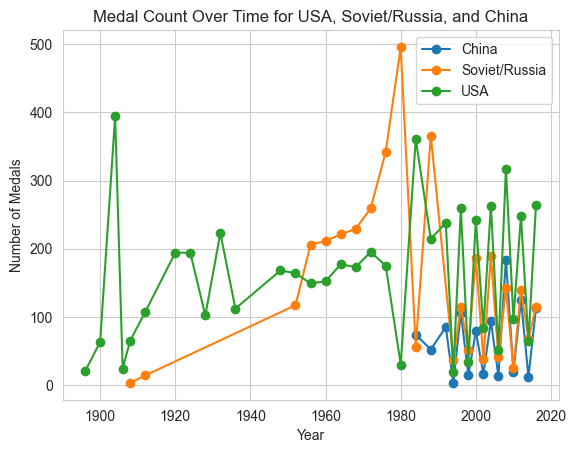

In [20]:
medals_per_year = medals.groupby(['Year', 'country_group']).size().reset_index(name='count')

for group, dfg in medals_per_year.groupby('country_group'):
    plt.plot(dfg['Year'], dfg['count'], marker='o', label=group)
plt.title('Medal Count Over Time for USA, Soviet/Russia, and China')
plt.ylabel('Number of Medals')
plt.xlabel('Year')
plt.legend()
plt.show()


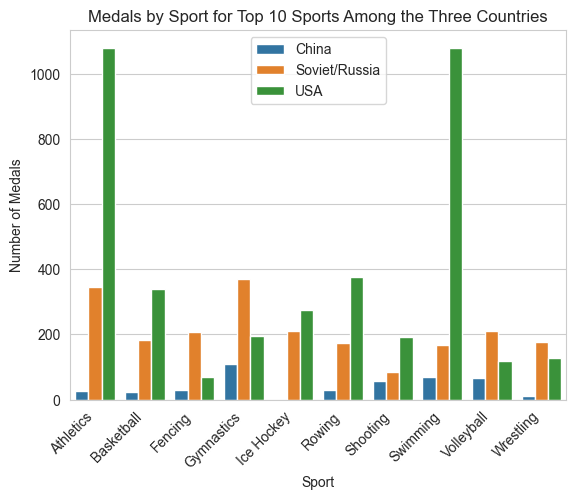

In [ ]:
medals_by_sport = medals.groupby(['Sport', 'country_group']).size().reset_index(name='count')

total_by_sport = medals_by_sport.groupby('Sport')['count'].sum().sort_values(ascending=False)
top_sports = total_by_sport.head(10).index.tolist()

filtered = medals_by_sport[medals_by_sport['Sport'].isin(top_sports)]

sns.barplot(data=filtered, x='Sport', y='count', hue='country_group')
plt.title('Medals by Sport for Top 10 Sports Among the Three Countries')
plt.ylabel('Number of Medals')
plt.xlabel('Sport')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.show()
